# Методы обработки и распознавания изображений¶

## Практическое занятие 4: Предобученные модели (Transfer learning)

Будем работать с датасетом, который не входит в набор стандартных датасетов библиотеки Keras, поэтому данные придется загружать из внешнего источника.

Загрузим датасет для бинарной классификации кошек и собак. Попробуем научить сеть различать кошек и собаки.

In [1]:
# Импортируем функцию для загрузки картинок из файлов и генератор картинок
from tensorflow.keras.preprocessing.image import load_img, ImageDataGenerator
import numpy as np
from matplotlib import pyplot as plt

I0000 00:00:1795086732.061028    8826 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795086733.384929    8826 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795086749.551479    8826 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


#### 1. Загрузка данных

In [ ]:
#!wget -c https://s3.amazonaws.com/content.udacity-data.com/nd089/Cat_Dog_data.zip
#!unzip -qq Cat_Dog_data.zip

"wget" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.
"unzip" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


Данные хранятся в папке `Cat_Dog_data` с разделением на поддиректории `train` и `test`.

Элементы каждого класса хранятся в своей директории (`cat` или `dog`).

In [3]:
import os.path

base_dir = 'Cat_Dog_data'

train_dir = os.path.join(base_dir, 'train')

test_dir = os.path.join(base_dir, 'test')

In [4]:
from os import listdir, sep
from os.path import abspath, basename, isdir
def tree(dir, padding= '  ', print_files=False):
    """
    Эта функция строит дерево поддиректорий и файлов для заданной директории

    Параметры
    ----------
    dir : str
        Path to needed directory
    padding : str
        String that will be placed in print for separating files levels
    print_files : bool
        "Print or not to print" flag
    """
    cmd = "find '%s'" % dir
    files = os.popen(cmd).read().strip().split('\n')
    padding = '|  '
    for file in files:
        level = file.count(os.sep)
        pieces = file.split(os.sep)
        symbol = {0:'', 1:'/'}[isdir(file)]
        if not print_files and symbol != '/':
            continue
        print (padding*level + pieces[-1] + symbol)

In [5]:
def plot_cats_dogs_samples(train_dir, N=4):
  """
    Эта функция строит N сэмплов каждого класса из датасета Cats vs Dogs

    Параметры
    ----------
    train_dir : str
        Directory with train Cats vs Dogs dataset
    N : int
        Number of samples for each class
  """
  import random
  fig, ax = plt.subplots(2,N,figsize=(5*N,5*2))

  for i,name in enumerate(['cat','dog']):
    filenames = os.listdir(os.path.join(train_dir,name))

    for j in range(N):
      sample = random.choice(filenames)
      image = load_img(os.path.join(train_dir,name,sample))
      ax[i][j].imshow(image)
      ax[i][j].set_xticks([])
      ax[i][j].set_yticks([])
      ax[i][j].set_title(name)
  plt.grid(False)
  plt.show()

In [6]:
# Посмотрим, как именно расположены директории с датасетом относительно друг друга
tree(base_dir,print_files=False)

Cat_Dog_data/
|  test/
|  |  cat/
|  |  dog/
|  train/
|  |  cat/
|  |  dog/


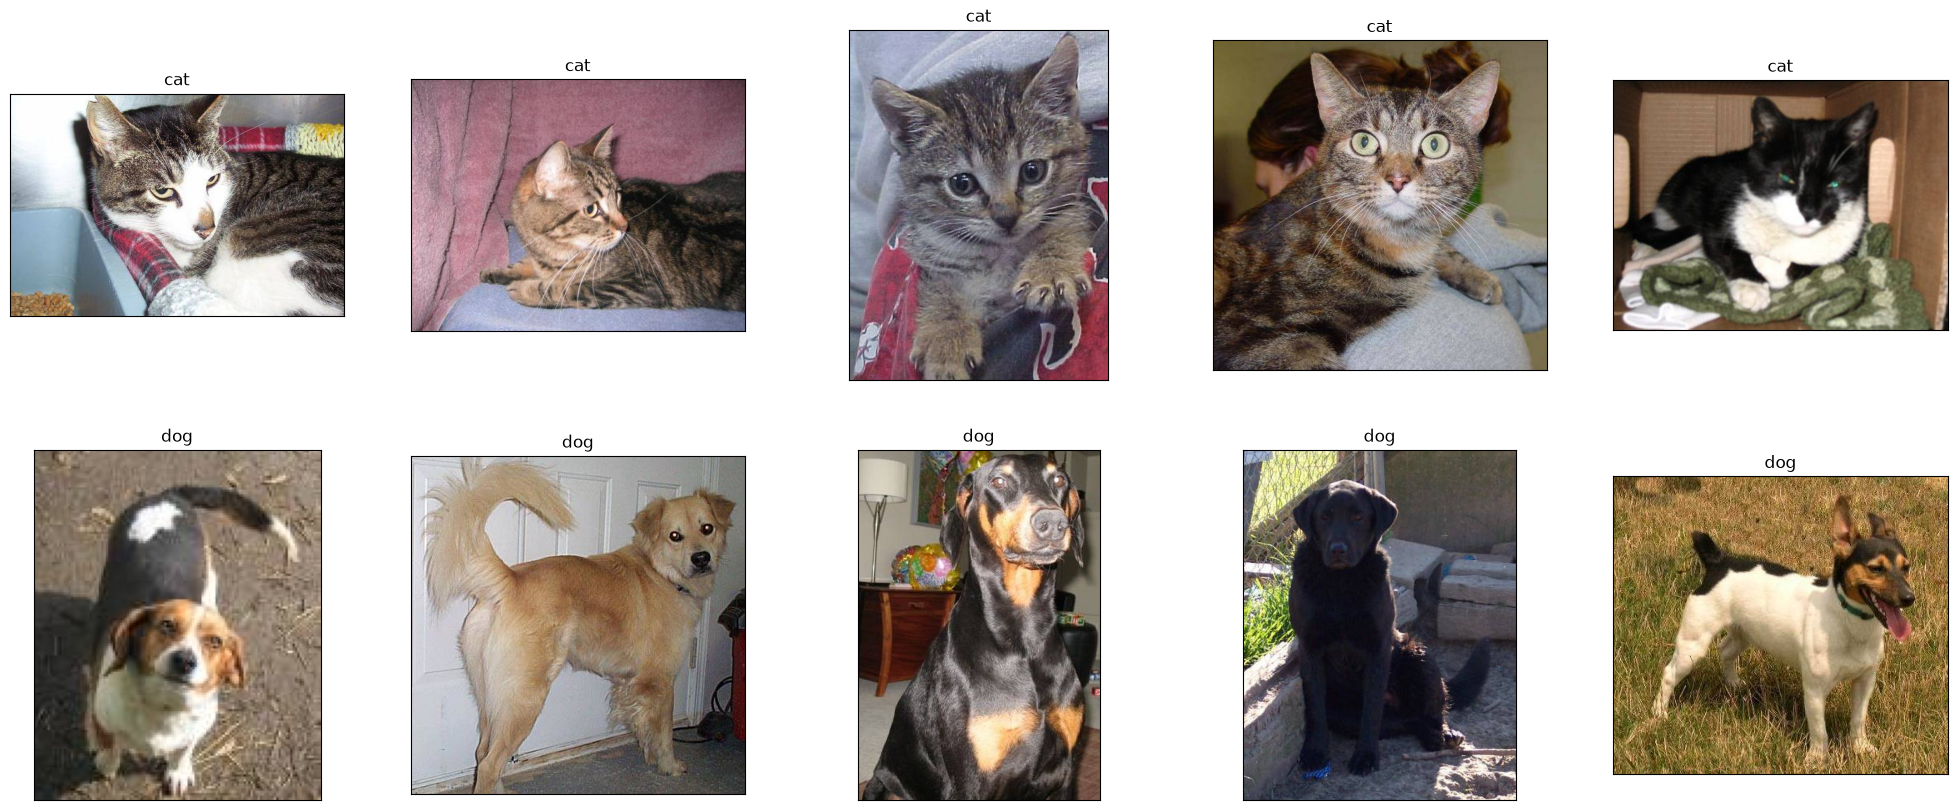

In [7]:
#Посмотрим на содержание датасета при помощи функции plot_cats_dogs_samples
plot_cats_dogs_samples(train_dir, N=5)

### 2. Подготовка данных


Такой формат хранения удобен для использования функции генератора изображений `flow_from_directory`.

Генератор не будет выкачивать все данные в оперативную память, а будет поочередно считывать из директорий нужные изображения и складывать их в батчи.

Создадим `ImageDataGenerator` для трейновой и тестовой выборок, поскольку обе выборки нужно доставать из директорий.

Укажем преобразование, нормализующее изображения

In [8]:
# Импортируем сам keras
import keras
# Последовательный тип модели
from keras.models import Sequential
# Импортируем полносвязный слой, слои активации и слой,
# превращающий картинку в вектор
from keras.layers import Dense, Activation, Flatten
# Импортируем сверточный слой, слои, фильтрующий максимальные значения из
# входных данных, слой "выключающий часть нейронов"
from keras.layers import Conv2D, MaxPooling2D, Dropout

In [9]:
# Эти библиотеки отключают лишние предупреждения от библиотек, в частности,
# tensorflow, чтобы не засорять вывод наших результатов
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
from tensorflow.python.util import deprecation
deprecation._PRINT_DEPRECATION_WARNINGS = False
import warnings
warnings.filterwarnings("ignore")

In [10]:
VALID_SPLIT = 0.2  # Берем 20% от train_dir как уменьшенный датасет
SEED = 42

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=VALID_SPLIT)

test_datagen = ImageDataGenerator(rescale=1./255)

Зададим поток тренировочных батчей из директории **train** и **test**;

Приведем все изображения к одному квадратному формату;

Укажем, что работаем с задачей бинарной классификации

In [11]:
#Теперь для создания генератора вместо метода flow мы пользуемся
# flow_from_directory

train_generator = train_datagen.flow_from_directory(
        train_dir,  # Путь к директории с трейновой выборкой
        target_size=(150, 150),  # Размер изображений, к которому нужно привести все данные
        batch_size=256,
        #Генератор автоматически расставит бинарные лейблы для классов cat и dog
        class_mode='binary',
        subset='validation',
        seed=SEED)


test_generator = test_datagen.flow_from_directory(
        test_dir,
        target_size=(150, 150),
        batch_size=256,
        class_mode='binary')

Found 4500 images belonging to 2 classes.
Found 2500 images belonging to 2 classes.


In [12]:
# Соотношение между номером класса и его названием запишем в словарь
LABEL_DICT={1:'dog',0:'cat'}

In [13]:
def plot_dataset_samples_grid(image_data, dataset_name='', N=8):
  """
    Эта функция строит NxN самплов из датасета image_data

    Параметры
    ----------
    image_data : array
        Array of shape
        (number_of_samples, image_width, image_height, number of channels)
        with images
    dataset_name : str
        Name of dataset to write in the title
    N : int
        Size of grid of samples
  """
  plt.figure(figsize=(10,10))
  data1=image_data[:N*N]

  image_width=image_data.shape[1]
  image_heigth=image_data.shape[2]

  if len(data1.shape)==4:
    image_channels=image_data.shape[3]
    data1 = data1.reshape(N, N,image_width,image_heigth, image_channels)
    data1 = np.transpose(data1,(0,2,1,3,4))
    data1 = data1.reshape(N*image_width,N*image_heigth,image_channels)
    plt.imshow(data1)

  elif len(data1.shape)==3:
    data1 = data1.reshape(N, N,image_width,image_heigth)
    data1 = np.transpose(data1,(0,2,1,3))
    data1 = data1.reshape(N*image_width,N*image_heigth)
    plt.imshow(data1,cmap='gray')
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.title('First '+ str(N*N) + ' '+dataset_name+ ' samples of training set')
  plt.show()

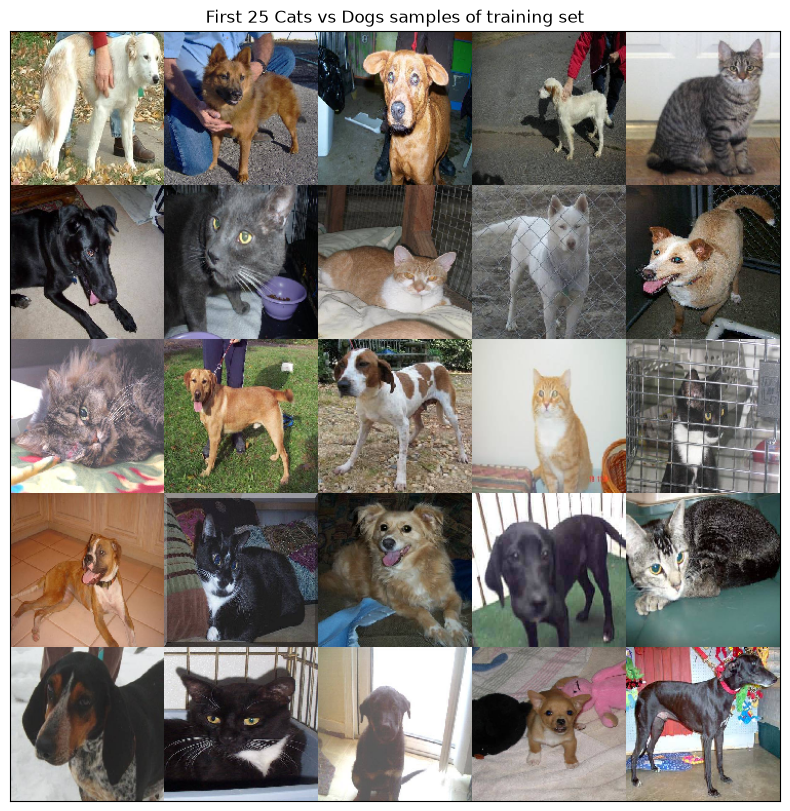

In [14]:
# train_generator является итератором, т.е., чтобы получить батч элементов
# нужно выполнить какую-то итерирующую функцию: например, цикл for
for img in train_generator:
  img=img[0]
  break

#Посмотрим, какие у нас вышли картинки при помощи функции plot_dataset_samples_grid
plot_dataset_samples_grid(img,'Cats vs Dogs', N=5)

### 3. Baseline
Для сравнения построим небольшую  baseline сверточную модель, состоящую из трех блоков **conv-maxpool** и пары полносвязных слоев.



Размер входящего изображения `input_shape`=($150$, $150$, $3$), активация последнего слоя - `sigmoid` вместо `softmax`, поскольку мы работаем с бинарной классификацией. На выходе мы получим вероятность от $0$ до $1$, что картинка принадлежит к классу $1$ (**dog**).

In [15]:
def define_model():
  # Создаем пустую модель
  model = Sequential()

#1й сверточный блок
  # Начинаем со сверточных слоев, указывая тип активации ReLU
  model.add(Conv2D(16, (3, 3), activation='relu', input_shape=(150, 150, 3)))
  # Здесь мы используем метод MaxPooling, который уменьшает размер обрабатываемого изображения,
  # выбирая из 4 пикселей 1 с максимальным значением, чтобы это быстрее считалось. (2,2) -> 1
  model.add(MaxPooling2D((2, 2)))

#2й сверточный блок
  model.add(Conv2D(32, (3, 3), activation='relu'))
  model.add(MaxPooling2D((2, 2)))

#3й сверточный блок
  model.add(Conv2D(64, (3, 3), activation='relu'))
  model.add(MaxPooling2D((2, 2)))

  # Разворачиваем данные в вектор
  model.add(Flatten())
  # Добавляем полносвязные слои:
  # ReLU активация скрытого слоя
  model.add(Dense(512, activation='relu'))
  # Sigmoid в качестве активации и одна выходная переменная -
  # вероятность, что картинка принадлежит к классу 1
  model.add(Dense(1, activation='sigmoid'))


  # Компилируем модель с функцией ошибки binary crossentropy, оптимизатором Адам
  # (оптимизатор, который со стандартным набором параметров может обучить эффективную
  # нейросеть), и метрикой - количеством правильно угаданных картинок.
  model.compile(loss='binary_crossentropy',
                  optimizer = 'adam',
                  metrics = ['accuracy'])
  return model

In [16]:
# Создаем новую модель
base_model = define_model()

I0000 00:00:1795086859.141693    8826 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [17]:
#Посмотрим, из чего наша модель состоит
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     9,470,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,494,561 (36.22 MB)

 Trainable params: 9,494,561 (36.22 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = base_model.fit(
      train_generator,
      epochs=10,
      validation_data=test_generator)

Epoch 1/10


I0000 00:00:1795086875.175447    8826 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1795086878.734761    9341 service.cc:153] XLA service 0x7a85c4004a10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795086878.734803    9341 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795086878.823978    9341 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795086879.172416    9341 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795086886.146433    9457 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1795086886.478342    9458 subprocess_compilation.cc:348] ptxas

 6/18 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.5098 - loss: 1.0438

I0000 00:00:1795086913.250905    9768 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 10228 bytes spill stores, 8892 bytes spill loads

I0000 00:00:1795086914.917844    9769 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_4', 96 bytes spill stores, 64 bytes spill loads



18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5122 - loss: 0.8083

W0000 00:00:1795086966.126106    9340 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.02GiB (rounded to 2164263168)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1795086966.131716    9340 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1795086966.131723    9340 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 33, Chunks in use: 33. 8.2KiB allocated for chunks. 8.2KiB in use in bin. 1.4KiB client-requested in use in bin.
I0000 00:00:1795086966.131733    9340 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 0, Chunks in use: 0. 0B allocated for chunks. 0B in use in bin. 0B client-requested in use in bin.
I0000 00:00:1795086966.131737    9340 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 6, Chunks in use: 5. 9.0KiB allocated for chunks. 7.8KiB in 

18/18 ━━━━━━━━━━━━━━━━━━━━ 116s 6s/step - accuracy: 0.5122 - loss: 0.8083 - val_accuracy: 0.5008 - val_loss: 0.6790
Epoch 2/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.5916 - loss: 0.6581 - val_accuracy: 0.5980 - val_loss: 0.6604
Epoch 3/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.6518 - loss: 0.6223 - val_accuracy: 0.6632 - val_loss: 0.6134
Epoch 4/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.7051 - loss: 0.5632 - val_accuracy: 0.6912 - val_loss: 0.5822
Epoch 5/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7498 - loss: 0.5082 - val_accuracy: 0.7156 - val_loss: 0.5633
Epoch 6/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.7762 - loss: 0.4726 - val_accuracy: 0.7264 - val_loss: 0.5536
Epoch 7/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8118 - loss: 0.4183 - val_accuracy: 0.7076 - val_loss: 0.5992
Epoch 8/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8213 - loss: 0.3923 - val_accuracy: 0.7224 - val_loss: 0.5667
Ep

Epoch 1/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.4942 - loss: 0.9675 - val_accuracy: 0.5180 - val_loss: 0.6913
Epoch 2/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.5713 - loss: 0.6811 - val_accuracy: 0.5776 - val_loss: 0.6711
Epoch 3/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.6142 - loss: 0.6532 - val_accuracy: 0.6056 - val_loss: 0.6509
Epoch 4/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.6591 - loss: 0.6151 - val_accuracy: 0.6372 - val_loss: 0.6293
Epoch 5/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.6682 - loss: 0.5951 - val_accuracy: 0.6768 - val_loss: 0.5969
Epoch 6/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7218 - loss: 0.5393 - val_accuracy: 0.6868 - val_loss: 0.5817
Epoch 7/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.7496 - loss: 0.5044 - val_accuracy: 0.7064 - val_loss: 0.5717
Epoch 8/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.7704 - loss: 0.4698 - val_accuracy: 0.7180 - val_loss: 0.5537
Epoch 9/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.8000 - loss: 0.4321 - val_accuracy: 0.7232 - val_loss: 0.5518
Epoch 10/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.8073 - loss: 0.4172 - val_accuracy: 0.7328 - val_loss: 0.5500

Epoch 1/7
176/176 [==============================] - 70s 400ms/step - loss: 0.6378 - accuracy: 0.6406 - val_loss: 0.5305 - val_accuracy: 0.7060
Epoch 2/7
176/176 [==============================] - 68s 386ms/step - loss: 0.4902 - accuracy: 0.7629 - val_loss: 0.5897 - val_accuracy: 0.7572
Epoch 3/7
176/176 [==============================] - 67s 380ms/step - loss: 0.4242 - accuracy: 0.8044 - val_loss: 0.5435 - val_accuracy: 0.7836
Epoch 4/7
176/176 [==============================] - 66s 375ms/step - loss: 0.3693 - accuracy: 0.8354 - val_loss: 0.4427 - val_accuracy: 0.7840
Epoch 5/7
176/176 [==============================] - 66s 377ms/step - loss: 0.3105 - accuracy: 0.8670 - val_loss: 0.4172 - val_accuracy: 0.8044
Epoch 6/7
176/176 [==============================] - 67s 378ms/step - loss: 0.2449 - accuracy: 0.8980 - val_loss: 0.5828 - val_accuracy: 0.8072
Epoch 7/7
176/176 [==============================] - 66s 376ms/step - loss: 0.1898 - accuracy: 0.9232 - val_loss: 0.4192 - val_accuracy: 0.8148

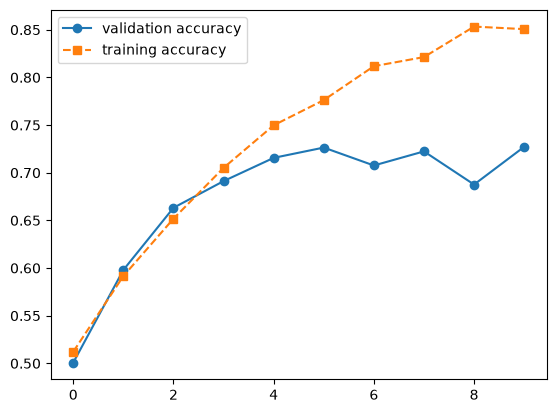

In [19]:
# Построим изменение точности на обучающей (оранжевая линия) и тестовой (синяя линия)
# выборках
plt.plot(history.history['val_accuracy'], '-o', label='validation accuracy')
plt.plot(history.history['accuracy'], '--s', label='training accuracy')
plt.legend();

In [20]:
# Взглянем на итоговые результаты классификации на тестовой выборке
# (функция ошибки, точность)
base_model.evaluate(test_generator)

10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 740ms/step - accuracy: 0.7272 - loss: 0.5965


[0.5964851379394531, 0.7271999716758728]

20/20 [==============================] - 7s 329ms/step

[0.5936983227729797, 0.8148000240325928]

Видно, что точность на тестовой выборке выходит на плато около  0.75 , а точность на обучающей выборке уверенно растет, поэтому с такой моделью улучшить точность на новых данных уже вряд ли выйдет.

## 4. Transfer learning

Использование предобученных моделей для новых задач

Как уже упоминалось ранее, есть архитектуры нейросетей, которые зарекомендовали себя в решении определенного класса задач, как, например, **VGG16**.

<img src="https://www.researchgate.net/profile/Max_Ferguson/publication/322512435/figure/download/fig3/AS:697390994567179@1543282378794/Fig-A1-The-standard-VGG-16-network-architecture-as-proposed-in-32-Note-that-only.png" width="700">


**VGG16** и подобные ей модели содержат большое количество параметров и обучение их с нуля может занять большое количество времени (а на домашнем ноутбуке это время стремится к бесконечности).

Кроме того, бывают задачи, где данных изначально небольшое количество и даже аугментация не сильно спасает положение, тогда обучение сверточной сети может быть не очень успешным.

Поэтому можно использовать модель, которая уже была кем-то предобучена, загрузить ее веса и дообучать только последние слои, подстраивая их под свою конкретную задачу.

#### Нам необходимо:

1.   Загрузить предобученную VGG16 модель без последних полносвязных слоев, отвечающих за конкретную задачу
2.   Построить свою полносвязную сеть для бинарной классификации кошек и собак
3.   Соединить две модели в одну.



### 1) Подготовим данные

Создадим `ImageDataGenerator` для трейновой и тестовой выборок,
указав преобразование, нормализующее изображения

In [21]:
#train_datagen = ImageDataGenerator(rescale=1./255)
#test_datagen = ImageDataGenerator(rescale=1./255)

VALID_SPLIT = 0.2  # Берем 20% от train_dir как уменьшенный датасет
SEED = 42

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=VALID_SPLIT)

test_datagen = ImageDataGenerator(rescale=1./255)

Изменим размеры картинок dataloader, поскольку модель **VGG16** принимает входные значения стандартизированного размера $224$х$224$x$3$.

Зададим поток тренировочных батчей из директории **train** и **test**.

Приведем все изображения к одному квадратному формату.

Укажем, что работаем с задачей бинарной классификации.

In [35]:
train_generator = train_datagen.flow_from_directory(
        train_dir,  # Путь к директории с трейновой выборкой
        target_size=(224, 224),  # Размер изображений, к которому нужно привести все данные
        batch_size=32,
        #Генератор автоматически расставит бинарные лейблы для классов cat и dog
        class_mode='binary',
        subset='validation',
        seed=SEED)


test_generator = test_datagen.flow_from_directory(
        test_dir,
        target_size=(224, 224),
        batch_size=32,
        class_mode='binary')

Found 4500 images belonging to 2 classes.
Found 2500 images belonging to 2 classes.


### 2) Загрузим VGG16

В библиотеке `Keras` уже представлены архитектуры **State-of-the-art** моделей, поэтому можно достать **VGG16** модель одной строчкой кода.

In [23]:
from keras.applications import vgg16 as vgg

Создадим **VGG** модель, в качестве параметра `weights` укажем `imagenet` - название
большого датасета с картинками, на котором сеть была натренирована;

`include_top` - False - не включать полносвязные слои вверху нейросети

In [25]:
vgg_model = vgg.VGG16(weights='imagenet',
                       include_top=False)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [26]:
#Посмотрим, из чего состоит VGG модель
vgg_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

Достанем последний слой `block5_pool` из **VGG** модели.

Над ним (или после него) построим наш классификатор.

In [27]:
last = vgg_model.get_layer('block5_pool').output

## 5. Global Average Pooling, Batch Normalization

**Global Average Pooling (GAP)**

Вместо того, чтобы изпользовать слой **Flatten** между сверточными и полносвязными слоями, который просто превращает выходные данные из свертки в вектор, можно посчитать среднее число для каждого канала свернутого изображения и передать полученный вектор полносвязным слоям.


**Batch Normalization**

Мы нормализуем входные данные нейросети, почему бы тогда не попробовать использовать нормализацию не только на входе, но и внутри модели?



### 3) Добавим небольшую нейросеть для бинарной классификации

In [28]:
# Модуль, с помощью которого мы будем "сшивать" последовательные модели
from keras import Model
# Импортируем Pooling по всему слою входных данных и нормализацию батчей
from keras.layers import GlobalAveragePooling2D, BatchNormalization

Добавим сверху слоя `last` **VGG** модели свои слои для классификации

In [29]:
# Добавим новые GAP (вместо FLatten) и BatchNormalization слои
x = GlobalAveragePooling2D()(last)
x = BatchNormalization()(x)

# Привычные полносвязные слои
x = Dense(512, activation='relu')(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
pred = Dense(1, activation='sigmoid')(x)

Объединим **VGG16** и **классификатор** в одного трансформера при помощи модуля `Model`

In [30]:
fin_model = Model(vgg_model.input, pred)

Теперь самое важное: нам не нужно изменять и так хорошо натренированные веса
исходной модели, поэтому мы **"замораживаем"** их, при обучении сети они будут использоваться
только для вычисления выходных данных

In [31]:
for layer in vgg_model.layers:
     layer.trainable = False

In [36]:
# Скомпилируем модель с функцией ошибки binary crossentropy, оптимизатором Адам
# (оптимизатор, который со стандартным набором параметров может обучить эффективную
# нейросеть), и метрикой - количеством правильно угаданных картинок.
fin_model.compile(loss='binary_crossentropy',
                  optimizer = 'adam',
                  jit_compile=False,
                  metrics = ['accuracy'])

In [37]:
fin_model.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 15,110,977 (57.64 MB)

 Trainable params: 395,265 (1.51 MB)

 Non-trainable params: 14,715,712 (56.14 MB)

In [38]:
# Обучим модель (5 эпох)
history_cnn = fin_model.fit(train_generator,
              epochs=3,
              validation_data=test_generator,
              shuffle=True)

Epoch 1/3


W0000 00:00:1795088723.834902    9340 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.55GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1795088723.835067    9340 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 800.14MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1795088723.870913    9340 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 800.14MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1795088723.890817    9340 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 800.14MiB with free

141/141 ━━━━━━━━━━━━━━━━━━━━ 43s 253ms/step - accuracy: 0.8624 - loss: 0.3105 - val_accuracy: 0.8668 - val_loss: 0.3966
Epoch 2/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 31s 217ms/step - accuracy: 0.9202 - loss: 0.1985 - val_accuracy: 0.9036 - val_loss: 0.2677
Epoch 3/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 31s 219ms/step - accuracy: 0.9347 - loss: 0.1574 - val_accuracy: 0.9136 - val_loss: 0.2105


176/176 ━━━━━━━━━━━━━━━━━━━━ 13231s 75s/step - accuracy: 0.8536 - loss: 0.3090 - val_accuracy: 0.9140 - val_loss: 0.3125

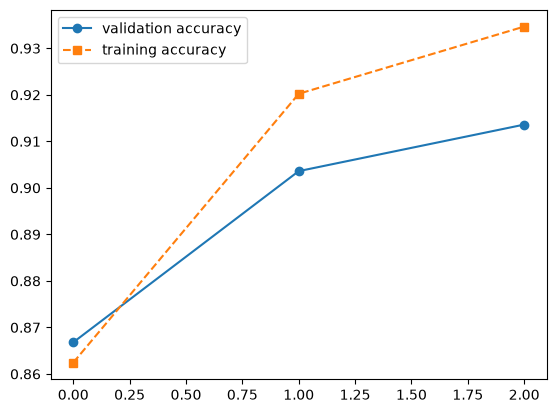

In [39]:
plt.plot(history_cnn.history['val_accuracy'], '-o', label='validation accuracy')
plt.plot(history_cnn.history['accuracy'], '--s', label='training accuracy')
plt.legend();
#plt.plot(history.history['val_accuracy'], '-o', label='validation accuracy')
#plt.plot(history.history['accuracy'], '--s', label='training accuracy')
#plt.legend();

In [40]:
fin_model.evaluate(test_generator)

79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - accuracy: 0.9136 - loss: 0.2105


[0.21049267053604126, 0.9136000275611877]

Использование предобученной модели **VGG** уже с 3-ей эпохи позволило нейросети достичь точности $>90$% на тестовой выборке!

### 4) Посмотрим на картинки с наибольшей ошибкой


Найдем все предсказания на тестовой выборке и посмотрим, на каких картинках нейросеть
ошиблась больше всего.

In [41]:
# Создадим генератор картинок из тестовой выборки
test_generator = test_datagen.flow_from_directory(
        test_dir,
        target_size=(224, 224),
        batch_size=256,
        class_mode='binary',shuffle=False)

Found 2500 images belonging to 2 classes.


In [42]:
def get_test_predictions(test_generator, model, dataset_len=2500):
  """
    Эта функция вытаскивает из генератора все предсказания

    Параметры
    ----------
    test_generator  : ImageDataGenerator
        Generator, producing batches (img, label)
    model : keras.model
        Model for getting predictions
    dataset_len : int
        Number of samples in generator

    Returns
    ----------
    preds_labels  : array
        Predicted labels
    preds_vec : array
        Predicted probabilities
    labels_vec : array
        True labels
    datas_vec : array
        Array of images
  """
  labels=[]
  preds=[]
  datas=[]

  samples=0
  for i,batch in enumerate(test_generator):
    data, label=batch
    labels.append(label)
    preds.append(model.predict(data))
    datas.append(data)
    samples+=len(data)
    if samples>=dataset_len:
      break

  labels_vec=np.hstack(labels)
  preds_vec=np.hstack([pred.reshape(-1,) for pred in preds])
  datas_vec=np.vstack(datas)
  preds_labels=preds_vec.copy()
  preds_labels[preds_labels<0.5]=0
  preds_labels[preds_labels>=0.5]=1

  return preds_labels, preds_vec, labels_vec, datas_vec

In [43]:
preds_labels, preds_vec, labels_vec, datas_vec = get_test_predictions(test_generator, fin_model)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step


Найдем вектор ошибок, который для каждого предсказания `preds_labels[i]`
будет содержать значение **True**, если модель ошиблась и **False**, если угадала `labels_vec[i]` верно.


In [44]:
errors = labels_vec!=preds_labels

In [45]:
def display_errors(errors_index,img_errors,pred_errors, obs_errors):
    """
    Эта функция показывает 6 картинок с предсказанными и настоящими классами
    """
    label_dict={0.:'cat',1.:'dog'}
    n = 0
    nrows = 5
    ncols = 5
    fig, ax = plt.subplots(nrows,ncols,sharex=True,sharey=True,figsize=(15,10))
    for row in range(nrows):
        for col in range(ncols):
            error = errors_index[n]
            ax[row,col].imshow((img_errors[error]).reshape((224,224,3)),cmap='gray')
            ax[row,col].set_title("Predicted label :{}\nTrue label :{}".format(label_dict[pred_errors[error]],label_dict[obs_errors[error]]))
            n += 1
    plt.tight_layout()

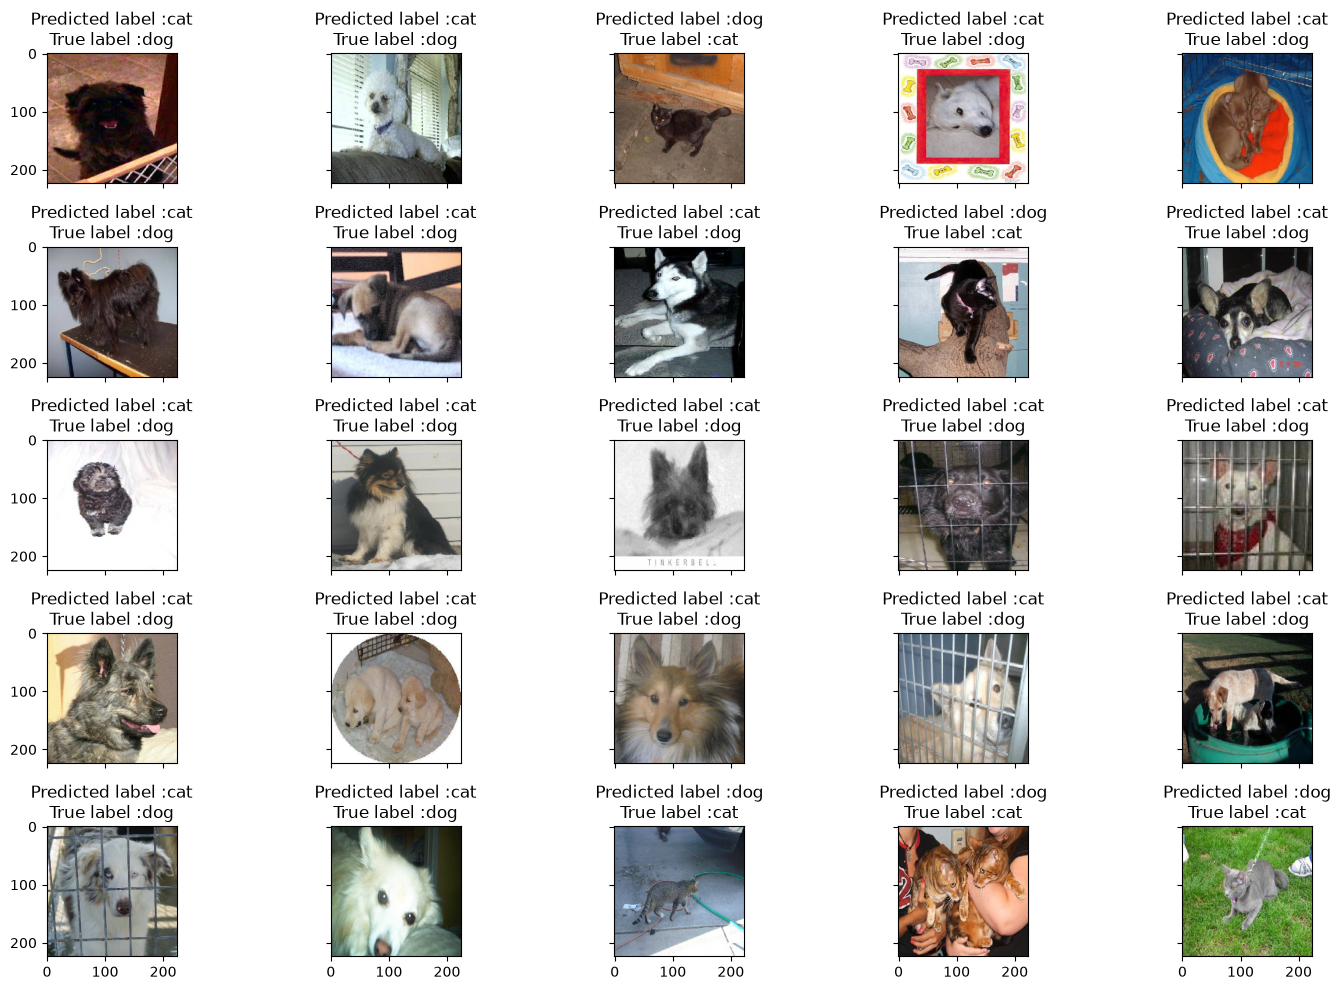

In [46]:
# Выделим из векторов предсказаний и настоящих лейблов только те,
# где нейросеть допустила ошибку
Y_pred_classes_errors = preds_labels[errors]
Y_pred_errors = preds_vec[errors]
Y_true_errors = labels_vec[errors]
X_val_errors = datas_vec[errors]

# Вероятности неправильно предсказанных классов
Y_pred_errors_prob = Y_pred_errors

# Вероятности, соответствующие правильным классам
true_prob_errors = 1-Y_pred_errors

# Разница вероятностей правильного и неправильного классов
delta_pred_true_errors = np.abs(Y_pred_errors_prob - true_prob_errors)

# Отсортированный списоц разниц вероятностей
sorted_dela_errors = np.argsort(delta_pred_true_errors)

# 25 наибольших ошибок
most_important_errors = sorted_dela_errors[-25:]

# Построим самые ошибочные rfhnbyrb
display_errors(most_important_errors, X_val_errors, Y_pred_classes_errors, Y_true_errors)

### Задание
Попробуйте улучшить результаты работы модели при помощи:

a.	Aугментации исходных данных (Добавить в ImageDataGenerator различные трансформации)

b.	Увеличения числа обучаемых параметров.

Чем ближе слои модели к выходному слою, тем больше веса зависят от конкретной задачи.
Изначально мы заморозили все слои модели vgg_model, теперь можно заморозить, например, первые 15 слоев, а остальные сделать обучаемыми.


In [49]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import vgg16 as vgg
import numpy as np
import matplotlib.pyplot as plt
import os

SEED = 42
BATCH_SIZE = 8
EPOCHS = 3
FINE_TUNE_EPOCHS = 3
keras.utils.set_random_seed(SEED)
train_dir = os.path.join('Cat_Dog_data', 'train')
test_dir = os.path.join('Cat_Dog_data', 'test')

plain_datagen = ImageDataGenerator(
    preprocessing_function=vgg.preprocess_input, validation_split=0.2)
aug_datagen = ImageDataGenerator(
    preprocessing_function=vgg.preprocess_input,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest')

def make_train_generator(datagen):
    return datagen.flow_from_directory(
        train_dir, target_size=(224, 224), batch_size=BATCH_SIZE,
        class_mode='binary', subset='training', shuffle=True, seed=SEED)

train_plain = make_train_generator(plain_datagen)
train_aug = make_train_generator(aug_datagen)
valid_data = plain_datagen.flow_from_directory(
    train_dir, target_size=(224, 224), batch_size=BATCH_SIZE,
    class_mode='binary', subset='validation', shuffle=False)
test_data = ImageDataGenerator(
    preprocessing_function=vgg.preprocess_input).flow_from_directory(
        test_dir, target_size=(224, 224), batch_size=BATCH_SIZE,
        class_mode='binary', shuffle=False)

backbone = vgg.VGG16(
    weights='imagenet', include_top=False, input_shape=(224, 224, 3))
backbone.trainable = False
inputs = keras.Input(shape=(224, 224, 3))
x = backbone(inputs)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Dense(512, activation='relu')(x)
x = keras.layers.Dense(256, activation='relu')(x)
x = keras.layers.Dropout(0.5)(x)
outputs = keras.layers.Dense(1, activation='sigmoid')(x)
assignment_model = keras.Model(inputs, outputs)
initial_weights = assignment_model.get_weights()

def compile_assignment(learning_rate):
    assignment_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy', metrics=['accuracy'])

def fit_assignment(generator, epochs):
    return assignment_model.fit(
        generator, validation_data=valid_data, epochs=epochs,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=2, restore_best_weights=True)])

results = []
def evaluate_assignment(name):
    test_data.reset()
    metrics = assignment_model.evaluate(test_data, return_dict=True)
    results.append((name, metrics['loss'], metrics['accuracy']))


Found 18000 images belonging to 2 classes.
Found 18000 images belonging to 2 classes.
Found 4500 images belonging to 2 classes.
Found 2500 images belonging to 2 classes.


In [50]:
compile_assignment(1e-3)
history_plain = fit_assignment(train_plain, EPOCHS)
evaluate_assignment('Frozen VGG16')


Epoch 1/3


I0000 00:00:1795089525.344072    9343 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_20051__.68
W0000 00:00:1795089536.092156    9343 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 461.70MiB (rounded to 484126208)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1795089536.092286    9343 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1795089536.092292    9343 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 95, Chunks in use: 95. 23.8KiB allocated for chunks. 23.8KiB in use in bin. 3.3KiB client-requested in use in bin.
I0000 00:00:1795089536.092298    9343 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 6, Chunks in use: 6. 3.2KiB allocated for chunks. 3.2KiB in use in bin. 3.0KiB client-requested in use in bin.
I0000 0

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9358 - loss: 0.1627

W0000 00:00:1795089920.189159    9343 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.15GiB (rounded to 2308964864)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1795089920.189362    9343 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1795089920.189366    9343 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 118, Chunks in use: 117. 29.5KiB allocated for chunks. 29.2KiB in use in bin. 3.5KiB client-requested in use in bin.
I0000 00:00:1795089920.189372    9343 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 7, Chunks in use: 6. 4.0KiB allocated for chunks. 3.2KiB in use in bin. 3.0KiB client-requested in use in bin.
I0000 00:00:1795089920.189375    9343 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 31, Chunks in use: 31. 36.5KiB allocated for

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 515s 168ms/step - accuracy: 0.9358 - loss: 0.1627 - val_accuracy: 0.9767 - val_loss: 0.0645
Epoch 2/3
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 174s 77ms/step - accuracy: 0.9521 - loss: 0.1264 - val_accuracy: 0.9778 - val_loss: 0.0655
Epoch 3/3
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 117s 52ms/step - accuracy: 0.9616 - loss: 0.1038 - val_accuracy: 0.9778 - val_loss: 0.0616
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9764 - loss: 0.0639


In [52]:
assignment_model.set_weights(initial_weights)
keras.utils.set_random_seed(SEED)
compile_assignment(1e-3)
history_aug = fit_assignment(train_aug, EPOCHS)
evaluate_assignment('Augmentation')


Epoch 1/3


I0000 00:00:1795090518.219240    9341 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_58363__.68


2250/2250 ━━━━━━━━━━━━━━━━━━━━ 256s 112ms/step - accuracy: 0.9286 - loss: 0.1775 - val_accuracy: 0.9787 - val_loss: 0.0585
Epoch 2/3
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 198s 88ms/step - accuracy: 0.9456 - loss: 0.1408 - val_accuracy: 0.9796 - val_loss: 0.0589
Epoch 3/3
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 179s 80ms/step - accuracy: 0.9504 - loss: 0.1291 - val_accuracy: 0.9804 - val_loss: 0.0571
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.9720 - loss: 0.0675


In [53]:
backbone.trainable = True
for index, layer in enumerate(backbone.layers):
    layer.trainable = index >= 15

print('Trainable VGG16 layers:', [layer.name for layer in backbone.layers if layer.trainable])
print('Trainable parameters:', sum(int(np.prod(w.shape)) for w in assignment_model.trainable_weights))
compile_assignment(1e-5)
history_fine = fit_assignment(train_aug, FINE_TUNE_EPOCHS)
evaluate_assignment('Augmentation + fine-tuning')


Trainable VGG16 layers: ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']
Trainable parameters: 7474689
Epoch 1/3


I0000 00:00:1795091205.623321    9338 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_97342__.68
W0000 00:00:1795091216.455000    9338 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 579.06MiB (rounded to 607191552)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1795091216.455147    9338 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1795091216.455151    9338 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 141, Chunks in use: 140. 35.2KiB allocated for chunks. 35.0KiB in use in bin. 3.8KiB client-requested in use in bin.
I0000 00:00:1795091216.455156    9338 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 7, Chunks in use: 6. 4.0KiB allocated for chunks. 3.2KiB in use in bin. 3.0KiB client-requested in use in bin.
I0000

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 233s 87ms/step - accuracy: 0.9611 - loss: 0.1002 - val_accuracy: 0.9864 - val_loss: 0.0443
Epoch 2/3
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 181s 81ms/step - accuracy: 0.9724 - loss: 0.0731 - val_accuracy: 0.9842 - val_loss: 0.0461
Epoch 3/3
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 180s 80ms/step - accuracy: 0.9761 - loss: 0.0677 - val_accuracy: 0.9860 - val_loss: 0.0451
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.9804 - loss: 0.0484


Experiment                        Test loss  Test accuracy
Frozen VGG16                         0.0639        97.64%
Augmentation                         0.0675        97.20%
Augmentation + fine-tuning           0.0484        98.04%


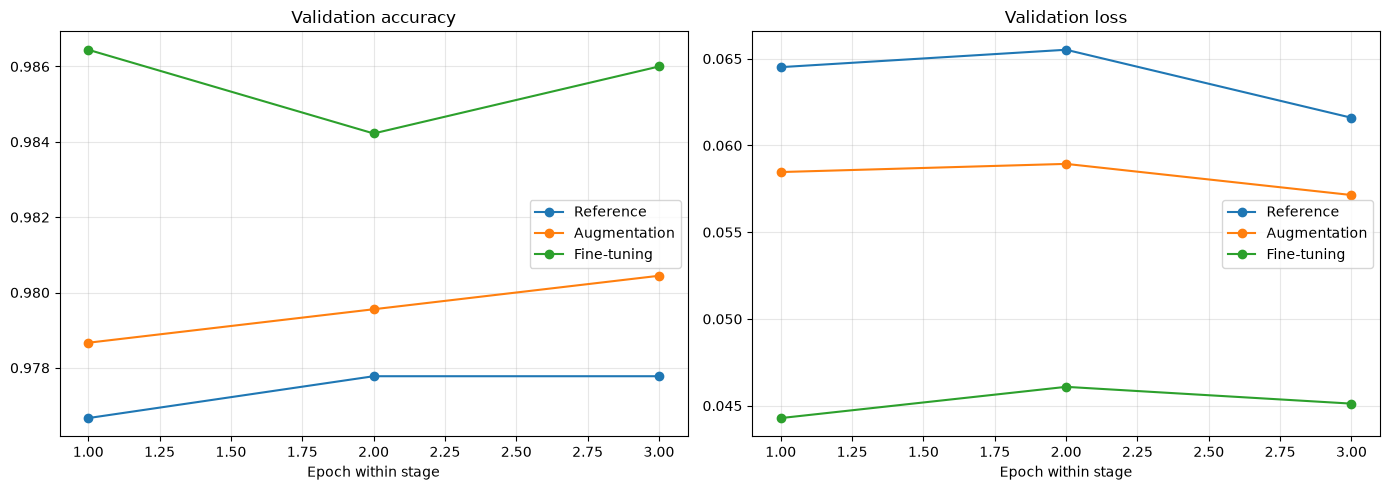

Augmentation accuracy change: -0.44 percentage points
Fine-tuning accuracy change: +0.84 percentage points
Augmentation adds training-image variation; fine-tuning adapts the final convolutional layers. Assess their benefit using the measured results. Use validation only for hyperparameter selection.


In [54]:
print(f"{'Experiment':<32} {'Test loss':>10} {'Test accuracy':>14}")
for name, loss, accuracy in results:
    print(f'{name:<32} {loss:>10.4f} {accuracy:>13.2%}')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, history in [('Reference', history_plain), ('Augmentation', history_aug), ('Fine-tuning', history_fine)]:
    epochs = range(1, len(history.history['loss']) + 1)
    axes[0].plot(epochs, history.history['val_accuracy'], '-o', label=name)
    axes[1].plot(epochs, history.history['val_loss'], '-o', label=name)
for ax, title in zip(axes, ['Validation accuracy', 'Validation loss']):
    ax.set_title(title)
    ax.set_xlabel('Epoch within stage')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()
base_accuracy, aug_accuracy, fine_accuracy = [row[2] for row in results]
print(f'Augmentation accuracy change: {(aug_accuracy - base_accuracy) * 100:+.2f} percentage points')
print(f'Fine-tuning accuracy change: {(fine_accuracy - aug_accuracy) * 100:+.2f} percentage points')
print('Augmentation adds training-image variation; fine-tuning adapts the final convolutional layers. Assess their benefit using the measured results. Use validation only for hyperparameter selection.')
